# Part I — Bank Term-Deposit Marketing Dataset Analysis

**Data Analytics I — Assignment 1**

This notebook analyses the `bank.csv` dataset covering education distribution, age–contact
engagement analysis, account balance composition, and dataset refinement.

## 1. Libraries and Setup

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

# Visual style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'figure.dpi': 100,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 16
})

COLORS = {
    'primary': '#2E86AB', 'secondary': '#A23B72', 'accent': '#F18F01',
    'success': '#2CA02C', 'danger': '#D32F2F', 'neutral': '#636363',
    'palette': ['#2E86AB', '#A23B72', '#F18F01', '#2CA02C', '#D32F2F',
                '#8E44AD', '#16A085', '#E74C3C']
}


def cramers_v(contingency_table):
    """Calculate Cramér's V for a contingency table."""
    chi2 = stats.chi2_contingency(contingency_table)[0]
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1
    return np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0.0


def eta_squared(groups, overall):
    """Calculate eta-squared effect size for ANOVA."""
    grand_mean = overall.mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    ss_total = sum((overall - grand_mean) ** 2)
    return ss_between / ss_total if ss_total > 0 else 0


print('Libraries loaded successfully.')

Libraries loaded successfully.


## 2. Dataset Loading and Inspection

In [70]:
bank = pd.read_csv('bank.csv')
print(f'Shape: {bank.shape[0]:,} rows × {bank.shape[1]} columns')
print(f'\nColumn data types:\n{bank.dtypes}')
print(f'\nFirst 5 rows:')
bank.head()

Shape: 11,162 rows × 17 columns

Column data types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object

First 5 rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


## 3. Data Cleaning

In [71]:
# Check for missing values
print('Missing values per column:')
print(bank.isnull().sum())
print(f'\nDuplicate rows: {bank.duplicated().sum()}')

# Inspect categorical columns for 'unknown' encoded values
cat_cols = bank.select_dtypes(include='object').columns
print('\nUnique values in categorical columns:')
for col in cat_cols:
    print(f'  {col}: {bank[col].unique()}')

Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64



Duplicate rows: 0

Unique values in categorical columns:
  job: ['admin.' 'technician' 'services' 'management' 'retired' 'blue-collar'
 'unemployed' 'entrepreneur' 'housemaid' 'unknown' 'self-employed'
 'student']
  marital: ['married' 'single' 'divorced']
  education: ['secondary' 'tertiary' 'primary' 'unknown']
  default: ['no' 'yes']
  housing: ['yes' 'no']
  loan: ['no' 'yes']
  contact: ['unknown' 'cellular' 'telephone']
  month: ['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']
  poutcome: ['unknown' 'other' 'failure' 'success']
  deposit: ['yes' 'no']


### Cleaning Decisions

1. **No structural missing values (NaN)** — all 11,162 rows are complete.
2. **'unknown' values** exist in `education`, `contact`, and `poutcome`. These are not dropped;
   they are retained and treated as a separate category ('Not-reported') where appropriate.
3. **`pdays = -1`** means the client was not previously contacted — valid sentinel encoding, kept as-is.
4. **No duplicate rows** found.
5. **Negative balances** are valid (they represent overdrafts) — kept as-is.
6. **Duration** minimum is 2 seconds — all values are plausible.

---
## Question 1 — Education Distribution & Grouping [5 Marks]

**Objective:** Identify the education distribution, create meaningful broader categories,
and compare before vs. after grouping.

### 1.1 Unique Education Values

In [72]:
print('Unique education levels:', bank['education'].unique())
print(f'Number of unique levels: {bank["education"].nunique()}')

Unique education levels: ['secondary' 'tertiary' 'primary' 'unknown']
Number of unique levels: 4


### 1.2 Frequency and Percentage of Each Education Level

In [73]:
edu_counts = bank['education'].value_counts()
edu_pct = (bank['education'].value_counts(normalize=True) * 100).round(2)
edu_summary = pd.DataFrame({
    'Count': edu_counts,
    'Percentage (%)': edu_pct
})
print('Education Level Distribution:')
edu_summary

Education Level Distribution:


,Count,Percentage (%)
education,,
secondary,5476,49.06
tertiary,3689,33.05
primary,1500,13.44
unknown,497,4.45


### 1.3 Visualize Original Education Distribution

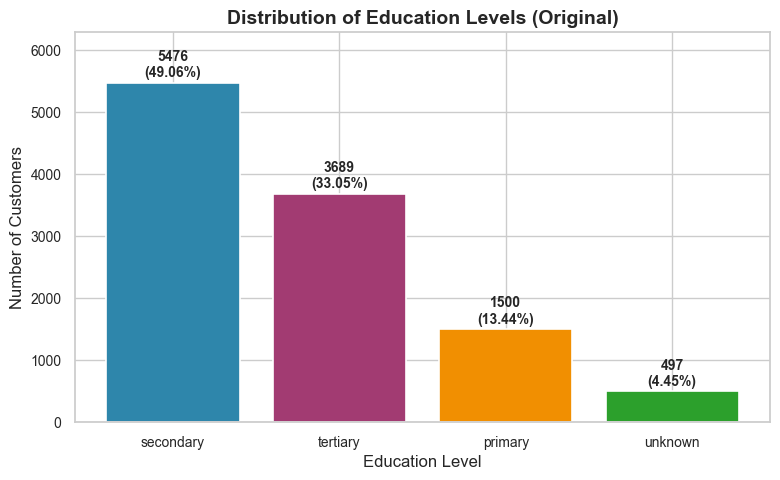

In [74]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(edu_counts.index, edu_counts.values, color=COLORS['palette'][:4],
              edgecolor='white', linewidth=1.2)
for bar, count, pct in zip(bars, edu_counts.values, edu_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50,
            f'{count}\n({pct}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title('Distribution of Education Levels (Original)', fontsize=14, fontweight='bold')
ax.set_xlabel('Education Level')
ax.set_ylabel('Number of Customers')
ax.set_ylim(0, max(edu_counts.values) * 1.15)
plt.tight_layout()
plt.show()

### 1.4 Create Meaningful Broader Categories

In [75]:
edu_mapping = {
    'primary': 'Basic',
    'secondary': 'Intermediate',
    'tertiary': 'Higher',
    'unknown': 'Not-reported'
}
bank['education_group'] = bank['education'].map(edu_mapping)

print('Education group mapping:')
for orig, grp in edu_mapping.items():
    print(f'  {orig:>10s}  →  {grp}')

Education group mapping:
     primary  →  Basic
   secondary  →  Intermediate
    tertiary  →  Higher
     unknown  →  Not-reported


### 1.5 Why This Mapping Is Meaningful

- **`primary` → `Basic`**: Represents foundational-level education only.
- **`secondary` → `Intermediate`**: Completed high-school or equivalent.
- **`tertiary` → `Higher`**: University or college education.
- **`unknown` → `Not-reported`**: Education level was not provided or recorded.
  Treating 'unknown' as a real education level would be misleading. Renaming it
  'Not-reported' makes it explicit that this is **missing information**, not a category.

This three-tier + not-reported scheme aligns with standard demographic grouping and
simplifies downstream analysis while preserving the data's information content.

### 1.6 Compare Before and After Grouping

In [76]:
edu_grp_counts = bank['education_group'].value_counts()
edu_grp_pct = (bank['education_group'].value_counts(normalize=True) * 100).round(2)

comparison = pd.DataFrame({
    'Original Category': list(edu_mapping.keys()),
    'Grouped Category': list(edu_mapping.values()),
    'Count': [edu_counts[k] for k in edu_mapping.keys()],
    'Percentage (%)': [edu_pct[k] for k in edu_mapping.keys()]
})
print('Before vs After Grouping Comparison:')
comparison

Before vs After Grouping Comparison:


,Original Category,Grouped Category,Count,Percentage (%)
0,primary,Basic,1500,13.44
1,secondary,Intermediate,5476,49.06
2,tertiary,Higher,3689,33.05
3,unknown,Not-reported,497,4.45


> Since each original level maps 1:1 to a group, counts remain identical.
> The value of grouping here is **semantic clarity**, not aggregation.

### 1.7 Visualize Grouped Categories

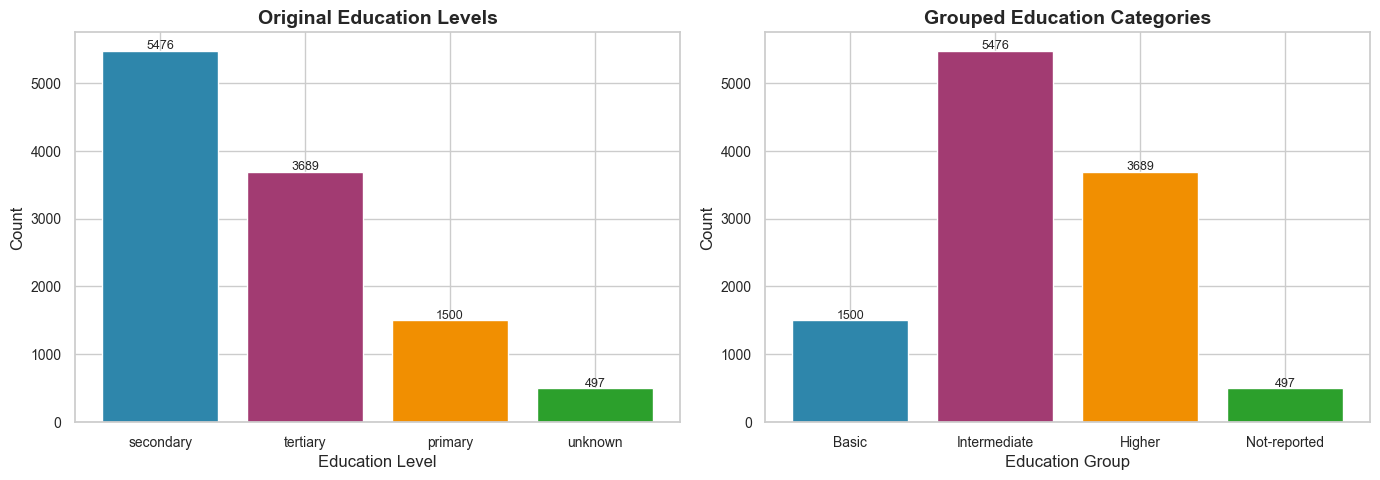

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original
axes[0].bar(edu_counts.index, edu_counts.values, color=COLORS['palette'][:4], edgecolor='white')
axes[0].set_title('Original Education Levels', fontweight='bold')
axes[0].set_xlabel('Education Level')
axes[0].set_ylabel('Count')
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'{int(bar.get_height())}', ha='center', fontsize=9)

# Grouped
grp_order = ['Basic', 'Intermediate', 'Higher', 'Not-reported']
grp_vals = [edu_grp_counts.get(g, 0) for g in grp_order]
axes[1].bar(grp_order, grp_vals, color=COLORS['palette'][:4], edgecolor='white')
axes[1].set_title('Grouped Education Categories', fontweight='bold')
axes[1].set_xlabel('Education Group')
axes[1].set_ylabel('Count')
for bar in axes[1].patches:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'{int(bar.get_height())}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### 1.8 How Grouping Improves Interpretability

1. **Semantic clarity**: 'Basic / Intermediate / Higher' are universally understood education
   tiers, whereas 'primary / secondary / tertiary' may be ambiguous across countries.
2. **Missing data flagged**: 'unknown' → 'Not-reported' prevents misinterpretation.
3. **Modelling ready**: These groups can be ordinal-encoded (Basic=1, Intermediate=2, Higher=3).
4. **Stakeholder-friendly**: Non-technical audiences understand the labels immediately.

---
## Question 2 — Age–Contact Engagement Intensity Relationship [10 Marks]

**Objective:** Analyse the relationship between `age` and `duration` (last marketing call
duration), create meaningful groups, and evaluate the effect of grouping.

### A. Analyse Age

In [78]:
age_summary = pd.DataFrame({
    'Statistic': ['Minimum', 'Maximum', 'Mean', 'Median', 'Std Dev', 'Q1 (25th)', 'Q3 (75th)'],
    'Value': [
        bank['age'].min(), bank['age'].max(),
        round(bank['age'].mean(), 2), bank['age'].median(),
        round(bank['age'].std(), 2),
        bank['age'].quantile(0.25), bank['age'].quantile(0.75)
    ]
})
print('Age Distribution Summary:')
age_summary

Age Distribution Summary:


,Statistic,Value
0,Minimum,18.00
1,Maximum,95.00
2,Mean,41.23
3,Median,39.00
4,Std Dev,11.91
5,Q1 (25th),32.00
6,Q3 (75th),49.00


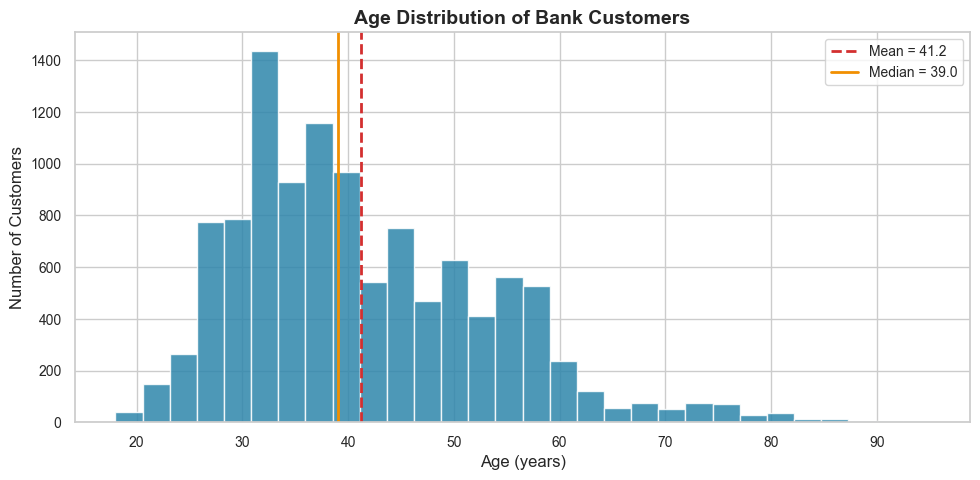

In [79]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(bank['age'], bins=30, color=COLORS['primary'], edgecolor='white', alpha=0.85)
ax.axvline(bank['age'].mean(), color=COLORS['danger'], linestyle='--', linewidth=2,
           label=f"Mean = {bank['age'].mean():.1f}")
ax.axvline(bank['age'].median(), color=COLORS['accent'], linestyle='-', linewidth=2,
           label=f"Median = {bank['age'].median():.1f}")
ax.set_title('Age Distribution of Bank Customers', fontweight='bold')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Number of Customers')
ax.legend()
plt.tight_layout()
plt.show()

**Age Distribution Analysis:**
- The distribution is **right-skewed** (positively skewed).
- Most customers are between 25 and 55 years old.
- The mean (41.2) is slightly higher than the median (39.0), confirming right skew.
- The IQR (Q1=32, Q3=49) captures the core working-age population.
- A small tail extends to age 95.

### B. Analyse Call Duration

In [80]:
dur_summary = pd.DataFrame({
    'Statistic': ['Minimum', 'Maximum', 'Mean', 'Median', 'Std Dev', 'Q1 (25th)', 'Q3 (75th)'],
    'Value': [
        bank['duration'].min(), bank['duration'].max(),
        round(bank['duration'].mean(), 2), bank['duration'].median(),
        round(bank['duration'].std(), 2),
        bank['duration'].quantile(0.25), bank['duration'].quantile(0.75)
    ]
})
print('Call Duration Distribution Summary (seconds):')
dur_summary

Call Duration Distribution Summary (seconds):


,Statistic,Value
0,Minimum,2.00
1,Maximum,3881.00
2,Mean,371.99
3,Median,255.00
4,Std Dev,347.13
5,Q1 (25th),138.00
6,Q3 (75th),496.00


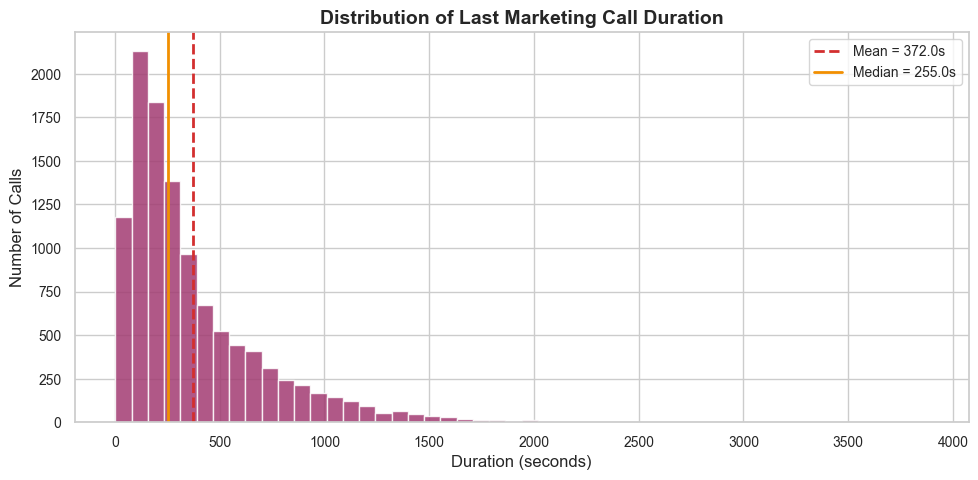

Duration skewness: 2.144


In [81]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(bank['duration'], bins=50, color=COLORS['secondary'], edgecolor='white', alpha=0.85)
ax.axvline(bank['duration'].mean(), color=COLORS['danger'], linestyle='--', linewidth=2,
           label=f"Mean = {bank['duration'].mean():.1f}s")
ax.axvline(bank['duration'].median(), color=COLORS['accent'], linestyle='-', linewidth=2,
           label=f"Median = {bank['duration'].median():.1f}s")
ax.set_title('Distribution of Last Marketing Call Duration', fontweight='bold')
ax.set_xlabel('Duration (seconds)')
ax.set_ylabel('Number of Calls')
ax.legend()
plt.tight_layout()
plt.show()

skewness = bank['duration'].skew()
print(f'Duration skewness: {skewness:.3f}')

**Call Duration Analysis:**
- The distribution is **strongly right-skewed** (skewness ≈ 2.07).
- 50% of calls last ≤ 255 seconds (~4.3 minutes).
- The **mean (372s) is much higher than the median (255s)** because extreme long calls pull the mean upward.
- Mean overestimates the 'typical' call duration; **median is the more robust central tendency measure**.
- Some calls lasted over 3,000 seconds (~50 minutes) — extreme outliers.

### C. Create Age Groups

In [82]:
print(f'Age range: {bank["age"].min()} to {bank["age"].max()}')

age_bins = [17, 29, 39, 49, 59, 100]  # 17 to include age 18
age_labels = ['Young Adult (18-29)', 'Early Adult (30-39)',
              'Middle Adult (40-49)', 'Older Adult (50-59)', 'Senior (60+)']

bank['age_group'] = pd.cut(bank['age'], bins=age_bins, labels=age_labels, right=True)

age_grp = bank['age_group'].value_counts().sort_index()
age_grp_pct = (bank['age_group'].value_counts(normalize=True).sort_index() * 100).round(2)

age_grp_summary = pd.DataFrame({
    'Age Group': age_grp.index.astype(str),
    'Count': age_grp.values,
    'Percentage (%)': age_grp_pct.values
})
print(f'Ungrouped observations: {bank["age_group"].isna().sum()}')
age_grp_summary

Age range: 18 to 95
Ungrouped observations: 0


,Age Group,Count,Percentage (%)
0,Young Adult (18-29),1551,13.90
1,Early Adult (30-39),4318,38.68
2,Middle Adult (40-49),2628,23.54
3,Older Adult (50-59),1885,16.89
4,Senior (60+),780,6.99


**Why these age groups were chosen:**
- **18–29 (Young Adult)**: Early career, typically lower savings.
- **30–39 (Early Adult)**: Established career, family formation, growing financial needs.
- **40–49 (Middle Adult)**: Peak earning years, significant financial commitments.
- **50–59 (Older Adult)**: Pre-retirement, typically higher balances.
- **60+ (Senior)**: Retirement age, different banking needs and contact preferences.
- Bins cover the entire observed range (18–95), leaving **zero observations ungrouped**.

### D. Create Contact-Intensity Groups

In [83]:
q1_dur = bank['duration'].quantile(0.25)
q2_dur = bank['duration'].quantile(0.50)
q3_dur = bank['duration'].quantile(0.75)

print(f'Duration Quartiles (from actual data):')
print(f'  Q1 (25th percentile): {q1_dur:.0f} seconds')
print(f'  Q2 (50th percentile): {q2_dur:.0f} seconds')
print(f'  Q3 (75th percentile): {q3_dur:.0f} seconds')

dur_bins = [-1, q1_dur, q2_dur, q3_dur, bank['duration'].max() + 1]
dur_labels = ['Brief', 'Standard', 'Extended', 'Deep-engagement']

bank['contact_intensity'] = pd.cut(bank['duration'], bins=dur_bins, labels=dur_labels, right=True)

ci_counts = bank['contact_intensity'].value_counts().sort_index()
ci_pct = (bank['contact_intensity'].value_counts(normalize=True).sort_index() * 100).round(2)

ci_summary = pd.DataFrame({
    'Contact Intensity': ci_counts.index.astype(str),
    'Duration Range (s)': [f'≤ {q1_dur:.0f}', f'{q1_dur:.0f}–{q2_dur:.0f}',
                           f'{q2_dur:.0f}–{q3_dur:.0f}', f'> {q3_dur:.0f}'],
    'Count': ci_counts.values,
    'Percentage (%)': ci_pct.values
})
ci_summary

Duration Quartiles (from actual data):
  Q1 (25th percentile): 138 seconds
  Q2 (50th percentile): 255 seconds
  Q3 (75th percentile): 496 seconds


,Contact Intensity,Duration Range (s),Count,Percentage (%)
0,Brief,≤ 138,2800,25.09
1,Standard,138–255,2792,25.01
2,Extended,255–496,2783,24.93
3,Deep-engagement,> 496,2787,24.97


### E. Compare Before and After Grouping

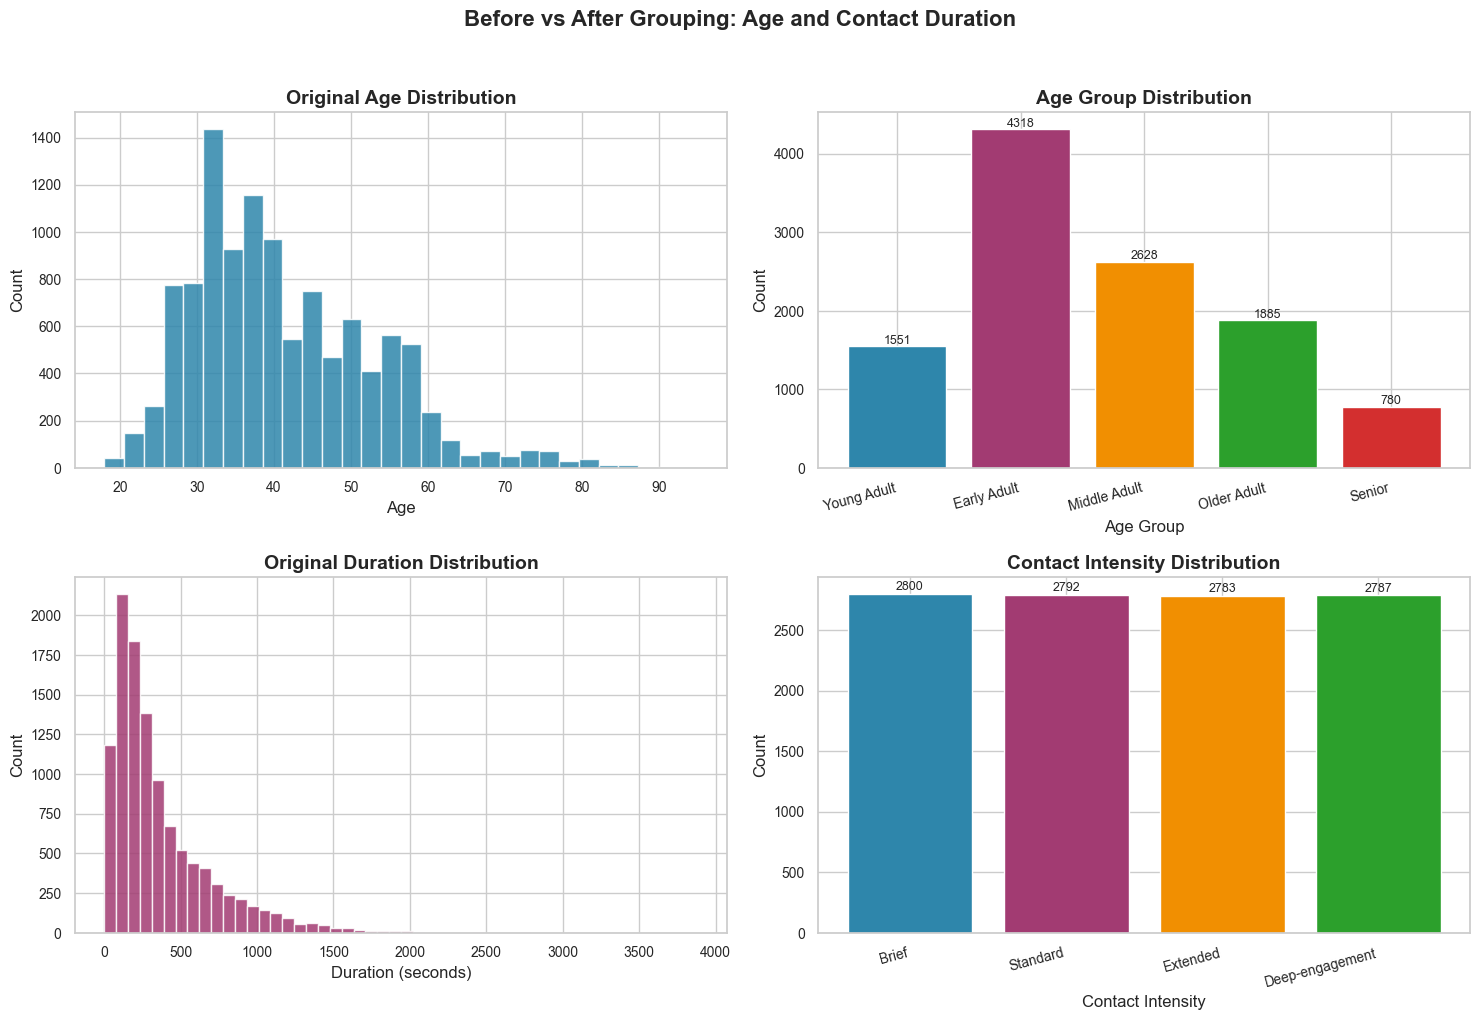

Age: 76 unique values → 5 groups
Duration: 1428 unique values → 4 groups


In [84]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Original age histogram
axes[0, 0].hist(bank['age'], bins=30, color=COLORS['primary'], edgecolor='white', alpha=0.85)
axes[0, 0].set_title('Original Age Distribution', fontweight='bold')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Count')

# Age group bar chart
age_grp_sorted = bank['age_group'].value_counts().sort_index()
short_labels = [str(x).split('(')[0].strip() for x in age_grp_sorted.index]
axes[0, 1].bar(range(len(age_grp_sorted)), age_grp_sorted.values,
               color=COLORS['palette'][:5], edgecolor='white')
axes[0, 1].set_xticks(range(len(age_grp_sorted)))
axes[0, 1].set_xticklabels(short_labels, rotation=15, ha='right')
axes[0, 1].set_title('Age Group Distribution', fontweight='bold')
axes[0, 1].set_xlabel('Age Group')
axes[0, 1].set_ylabel('Count')
for i, v in enumerate(age_grp_sorted.values):
    axes[0, 1].text(i, v + 30, str(v), ha='center', fontsize=9)

# Original duration histogram
axes[1, 0].hist(bank['duration'], bins=50, color=COLORS['secondary'], edgecolor='white', alpha=0.85)
axes[1, 0].set_title('Original Duration Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Duration (seconds)')
axes[1, 0].set_ylabel('Count')

# Contact intensity bar chart
ci_sorted = bank['contact_intensity'].value_counts().sort_index()
axes[1, 1].bar(range(len(ci_sorted)), ci_sorted.values,
               color=COLORS['palette'][:4], edgecolor='white')
axes[1, 1].set_xticks(range(len(ci_sorted)))
axes[1, 1].set_xticklabels(ci_sorted.index, rotation=15, ha='right')
axes[1, 1].set_title('Contact Intensity Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Contact Intensity')
axes[1, 1].set_ylabel('Count')
for i, v in enumerate(ci_sorted.values):
    axes[1, 1].text(i, v + 30, str(v), ha='center', fontsize=9)

plt.suptitle('Before vs After Grouping: Age and Contact Duration',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'Age: {bank["age"].nunique()} unique values → {bank["age_group"].nunique()} groups')
print(f'Duration: {bank["duration"].nunique()} unique values → {bank["contact_intensity"].nunique()} groups')

### F. Analyse Relationship Before Grouping (Scatter + Pearson Correlation)

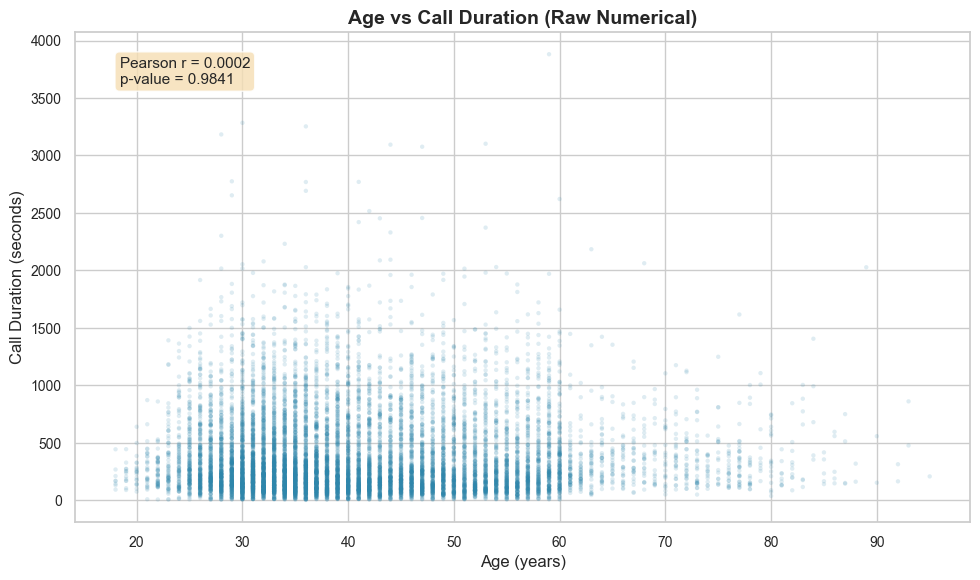

Pearson correlation coefficient: r = 0.0002
p-value: 0.9841


In [85]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(bank['age'], bank['duration'], alpha=0.15, s=10, color=COLORS['primary'], edgecolors='none')
ax.set_title('Age vs Call Duration (Raw Numerical)', fontweight='bold')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Call Duration (seconds)')

corr_coef, corr_pval = stats.pearsonr(bank['age'], bank['duration'])
ax.text(0.05, 0.95, f'Pearson r = {corr_coef:.4f}\np-value = {corr_pval:.4f}',
        transform=ax.transAxes, fontsize=11, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
plt.tight_layout()
plt.show()

print(f'Pearson correlation coefficient: r = {corr_coef:.4f}')
print(f'p-value: {corr_pval:.4f}')

**Correlation Interpretation:**
- r ≈ 0.0002 — an **extremely weak** (essentially zero) linear relationship.
- The p-value is not significant (p ≈ 0.98), confirming no meaningful linear association.
- The scatter plot shows no discernible pattern or trend.
- **Important:** Correlation does not imply causation — even if a relationship existed,
  we could not conclude that age *causes* longer or shorter calls.

### G. Analyse Relationship After Grouping (Contingency Table + Chi-Square)

In [86]:
# Contingency table — counts
contingency = pd.crosstab(bank['age_group'], bank['contact_intensity'])
print('Contingency Table (Counts):')
print(contingency)

# Row percentages
contingency_pct = pd.crosstab(bank['age_group'], bank['contact_intensity'], normalize='index')
contingency_pct = (contingency_pct * 100).round(2)
print('\nContingency Table (Row Percentages %):')
print(contingency_pct)

Contingency Table (Counts):
contact_intensity     Brief  Standard  Extended  Deep-engagement
age_group                                                       
Young Adult (18-29)     318       407       453              373
Early Adult (30-39)    1069      1082      1060             1107
Middle Adult (40-49)    753       634       582              659
Older Adult (50-59)     550       459       411              465
Senior (60+)            110       210       277              183

Contingency Table (Row Percentages %):
contact_intensity     Brief  Standard  Extended  Deep-engagement
age_group                                                       
Young Adult (18-29)   20.50     26.24     29.21            24.05
Early Adult (30-39)   24.76     25.06     24.55            25.64
Middle Adult (40-49)  28.65     24.12     22.15            25.08
Older Adult (50-59)   29.18     24.35     21.80            24.67
Senior (60+)          14.10     26.92     35.51            23.46


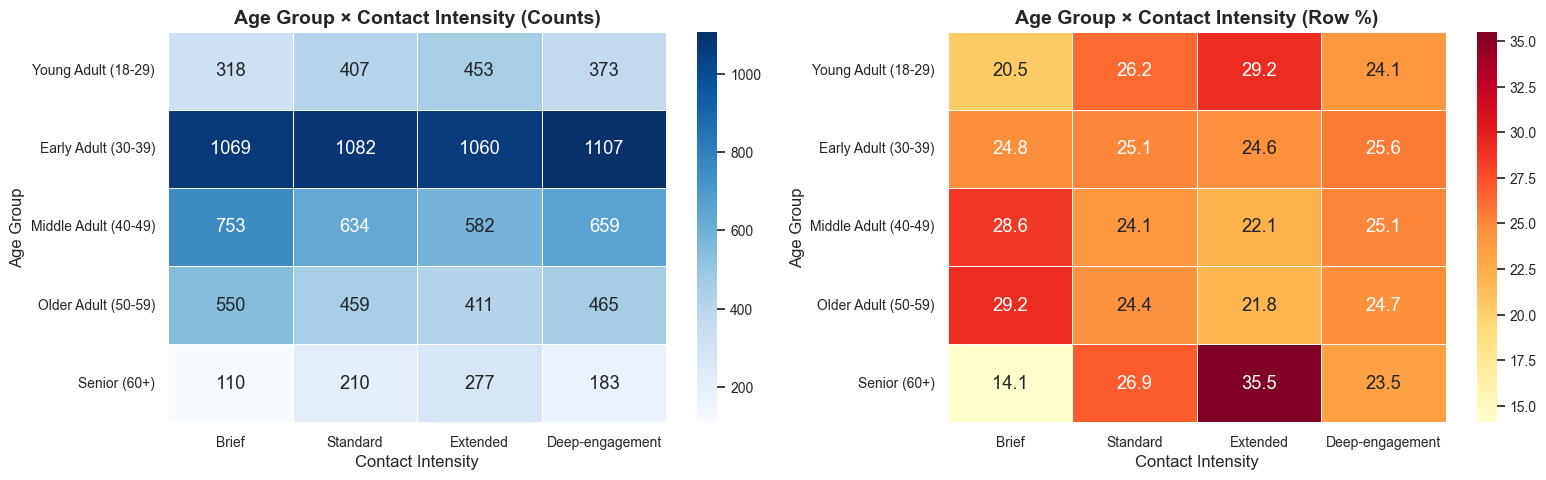

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(contingency, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            linewidths=0.5, linecolor='white')
axes[0].set_title('Age Group × Contact Intensity (Counts)', fontweight='bold')
axes[0].set_xlabel('Contact Intensity')
axes[0].set_ylabel('Age Group')

sns.heatmap(contingency_pct, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[1],
            linewidths=0.5, linecolor='white')
axes[1].set_title('Age Group × Contact Intensity (Row %)', fontweight='bold')
axes[1].set_xlabel('Contact Intensity')
axes[1].set_ylabel('Age Group')

plt.tight_layout()
plt.show()

In [88]:
# Chi-square test of independence
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
cramers = cramers_v(contingency)

print(f'Chi-Square Test of Independence:')
print(f'  Chi-square statistic: {chi2:.4f}')
print(f'  Degrees of freedom:   {dof}')
print(f'  p-value:              {p_value:.4f}')
print(f"  Cramér's V:           {cramers:.4f}")

if p_value < 0.05:
    print('\n→ p < 0.05: Reject H₀ — statistically significant association exists.')
else:
    print('\n→ p ≥ 0.05: Fail to reject H₀ — no statistically significant association.')

if cramers < 0.1:
    strength = 'negligible'
elif cramers < 0.3:
    strength = 'weak'
elif cramers < 0.5:
    strength = 'moderate'
else:
    strength = 'strong'
print(f"Cramér's V = {cramers:.4f} indicates a {strength} association.")

Chi-Square Test of Independence:
  Chi-square statistic: 144.1444
  Degrees of freedom:   12
  p-value:              0.0000
  Cramér's V:           0.0656

→ p < 0.05: Reject H₀ — statistically significant association exists.
Cramér's V = 0.0656 indicates a negligible association.


### H. Grouping Evaluation

#### Advantages
1. **Easier interpretation**: 'Early Adults mostly have Brief contacts' is more communicable than 'r = 0.0002'.
2. **Easier comparison**: Bar charts and contingency tables enable direct visual comparison.
3. **Easier visualization**: Grouped data fits naturally into bar charts, heatmaps, and mosaic plots.
4. **Useful for categorical modelling**: Decision trees, logistic regression with dummy variables benefit.

#### Limitations
1. **Loss of exact numerical information**: We lose distinction between age 30 and 39 — both 'Early Adult'.
2. **Boundary effects**: Customers aged 29 and 30 go to different groups despite being similar.
3. **Within-group heterogeneity**: Ages 60 and 95 are both 'Senior' despite very different characteristics.
4. **Can mask weak relationships**: Subtle non-linear patterns may be hidden further.

#### Conclusion
For this dataset, grouping improves interpretability substantially. The raw correlation (r ≈ 0) is too
weak to be actionable. Grouping provides a cleaner framework for comparison and reporting, and the
precision lost carries little analytical value. **The trade-off is justified.**

---
## Question 3 — Account Balance Composition & Group Performance [10 Marks]

**Objective:** Analyse the `balance` column, separate components, and examine
performance across age groups and contact-intensity groups.

### A. Overall Balance Distribution

In [89]:
bal_summary = pd.DataFrame({
    'Statistic': ['Minimum', 'Maximum', 'Mean', 'Median', 'Std Dev', 'Q1 (25th)', 'Q3 (75th)'],
    'Value': [
        bank['balance'].min(), bank['balance'].max(),
        round(bank['balance'].mean(), 2), bank['balance'].median(),
        round(bank['balance'].std(), 2),
        bank['balance'].quantile(0.25), bank['balance'].quantile(0.75)
    ]
})
print('Account Balance Distribution Summary:')
bal_summary

Account Balance Distribution Summary:


,Statistic,Value
0,Minimum,-6847.00
1,Maximum,81204.00
2,Mean,1528.54
3,Median,550.00
4,Std Dev,3225.41
5,Q1 (25th),122.00
6,Q3 (75th),1708.00


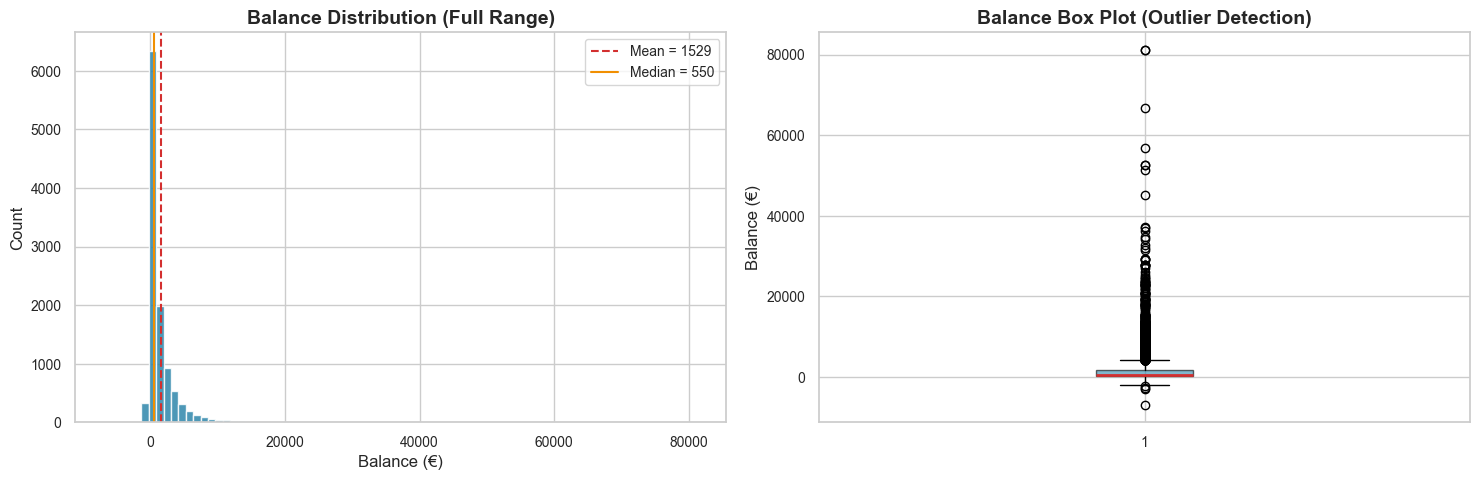

IQR: 1586, Lower fence: -2257, Upper fence: 4087
Outlier count: 1055 (9.5% of data)


In [90]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
axes[0].hist(bank['balance'], bins=80, color=COLORS['primary'], edgecolor='white', alpha=0.85)
axes[0].axvline(bank['balance'].mean(), color=COLORS['danger'], linestyle='--',
                label=f"Mean = {bank['balance'].mean():.0f}")
axes[0].axvline(bank['balance'].median(), color=COLORS['accent'], linestyle='-',
                label=f"Median = {bank['balance'].median():.0f}")
axes[0].set_title('Balance Distribution (Full Range)', fontweight='bold')
axes[0].set_xlabel('Balance (€)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Box plot
axes[1].boxplot(bank['balance'], vert=True, patch_artist=True,
                boxprops=dict(facecolor=COLORS['primary'], alpha=0.6),
                medianprops=dict(color=COLORS['danger'], linewidth=2))
axes[1].set_title('Balance Box Plot (Outlier Detection)', fontweight='bold')
axes[1].set_ylabel('Balance (€)')

plt.tight_layout()
plt.show()

# Outlier analysis
bal_q1 = bank['balance'].quantile(0.25)
bal_q3 = bank['balance'].quantile(0.75)
iqr = bal_q3 - bal_q1
lower_fence = bal_q1 - 1.5 * iqr
upper_fence = bal_q3 + 1.5 * iqr
outliers = bank[(bank['balance'] < lower_fence) | (bank['balance'] > upper_fence)]
print(f'IQR: {iqr:.0f}, Lower fence: {lower_fence:.0f}, Upper fence: {upper_fence:.0f}')
print(f'Outlier count: {len(outliers)} ({len(outliers)/len(bank)*100:.1f}% of data)')

### B. Separate Balance Components

In [91]:
bank['balance_category'] = np.select(
    [bank['balance'] > 0, bank['balance'] < 0, bank['balance'] == 0],
    ['Positive', 'Negative', 'Zero'],
    default='Unknown'
)

bal_comp = bank.groupby('balance_category').agg(
    Count=('balance', 'size'),
    Average_Balance=('balance', 'mean'),
    Median_Balance=('balance', 'median')
).round(2)
bal_comp['Percentage (%)'] = (bal_comp['Count'] / len(bank) * 100).round(2)
bal_comp = bal_comp[['Count', 'Percentage (%)', 'Average_Balance', 'Median_Balance']]
print('Balance Components:')
bal_comp

Balance Components:


,Count,Percentage (%),Average_Balance,Median_Balance
balance_category,,,,
Negative,688,6.16,-323.81,-239.0
Positive,9700,86.90,1781.89,730.0
Zero,774,6.93,0.00,0.0


**Component Definitions:**
- **Positive balance** (gain-like): Customers with savings/deposits > 0.
- **Negative balance** (loss-like): Customers with overdrafts/debt < 0.
- **Zero balance** (no capital activity): Customers with exactly 0 balance.

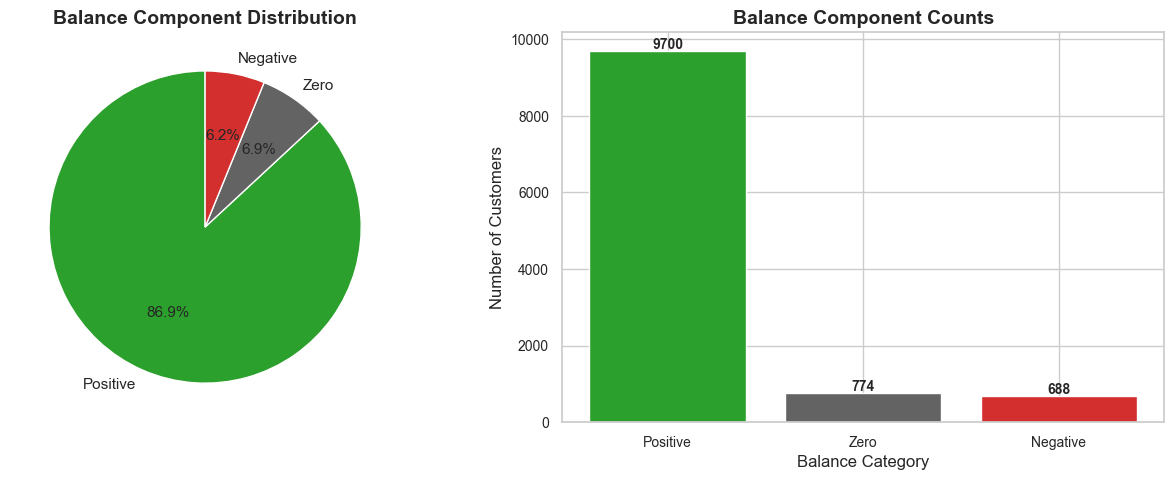

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

labels_order = ['Positive', 'Zero', 'Negative']
sizes = [bal_comp.loc[l, 'Count'] if l in bal_comp.index else 0 for l in labels_order]
colors_pie = [COLORS['success'], COLORS['neutral'], COLORS['danger']]

axes[0].pie(sizes, labels=labels_order, autopct='%1.1f%%', colors=colors_pie,
            startangle=90, textprops={'fontsize': 11})
axes[0].set_title('Balance Component Distribution', fontweight='bold')

axes[1].bar(labels_order, sizes, color=colors_pie, edgecolor='white')
for i, v in enumerate(sizes):
    axes[1].text(i, v + 50, str(v), ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('Balance Component Counts', fontweight='bold')
axes[1].set_xlabel('Balance Category')
axes[1].set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()

### C. Non-Zero Balance Distribution

In [93]:
positive_bal = bank[bank['balance'] > 0]['balance']
negative_bal = bank[bank['balance'] < 0]['balance']

print(f'Positive balances: {len(positive_bal):,} customers')
print(f'  Mean:   {positive_bal.mean():.2f}')
print(f'  Median: {positive_bal.median():.2f}')
print(f'  Std:    {positive_bal.std():.2f}')

print(f'\nNegative balances: {len(negative_bal):,} customers')
print(f'  Mean:   {negative_bal.mean():.2f}')
print(f'  Median: {negative_bal.median():.2f}')
print(f'  Std:    {negative_bal.std():.2f}')

Positive balances: 9,700 customers
  Mean:   1781.89
  Median: 730.00
  Std:    3386.01

Negative balances: 688 customers
  Mean:   -323.81
  Median: -239.00
  Std:    418.00


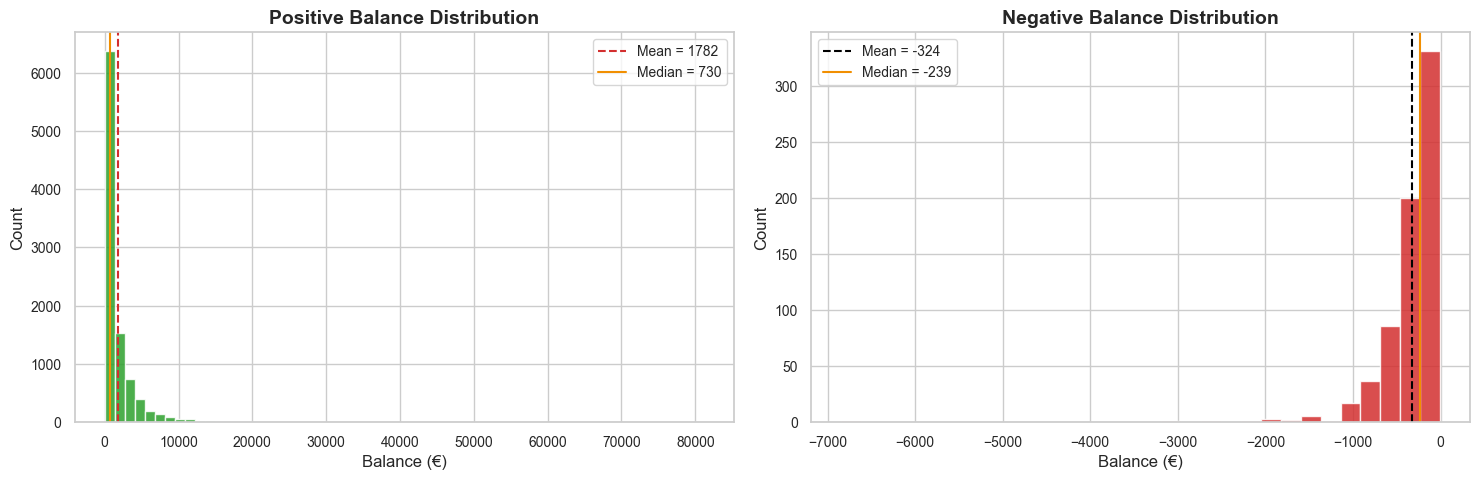

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(positive_bal, bins=60, color=COLORS['success'], edgecolor='white', alpha=0.85)
axes[0].axvline(positive_bal.mean(), color=COLORS['danger'], linestyle='--',
                label=f'Mean = {positive_bal.mean():.0f}')
axes[0].axvline(positive_bal.median(), color=COLORS['accent'], linestyle='-',
                label=f'Median = {positive_bal.median():.0f}')
axes[0].set_title('Positive Balance Distribution', fontweight='bold')
axes[0].set_xlabel('Balance (€)')
axes[0].set_ylabel('Count')
axes[0].legend()

axes[1].hist(negative_bal, bins=30, color=COLORS['danger'], edgecolor='white', alpha=0.85)
axes[1].axvline(negative_bal.mean(), color='black', linestyle='--',
                label=f'Mean = {negative_bal.mean():.0f}')
axes[1].axvline(negative_bal.median(), color=COLORS['accent'], linestyle='-',
                label=f'Median = {negative_bal.median():.0f}')
axes[1].set_title('Negative Balance Distribution', fontweight='bold')
axes[1].set_xlabel('Balance (€)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()

**Non-Zero Balance Analysis:**
- **Positive balances**: Strongly right-skewed. Most customers have moderate savings, but a few
  have very large balances (up to €81,204), pulling the mean well above the median.
- **Negative balances**: Concentrated near zero with a left tail. These represent customers
  in overdraft — typically smaller magnitude than positive balances.

### D. Age-Group Performance

In [95]:
age_bal = bank.groupby('age_group', observed=True).agg(
    Average_Net_Balance=('balance', 'mean'),
    Median_Balance=('balance', 'median'),
    Count=('balance', 'size'),
    Non_Zero_Count=('balance', lambda x: (x != 0).sum())
).round(2)
age_bal['Non_Zero_Proportion (%)'] = (age_bal['Non_Zero_Count'] / age_bal['Count'] * 100).round(2)
print('Balance Performance by Age Group:')
age_bal

Balance Performance by Age Group:


,Average_Net_Balance,Median_Balance,Count,Non_Zero_Count,Non_Zero_Proportion (%)
age_group,,,,,
Young Adult (18-29),1171.55,431.0,1551,1494,96.32
Early Adult (30-39),1350.98,490.5,4318,4009,92.84
Middle Adult (40-49),1483.56,551.5,2628,2414,91.86
Older Adult (50-59),1798.21,658.0,1885,1736,92.10
Senior (60+),2721.18,1245.5,780,735,94.23


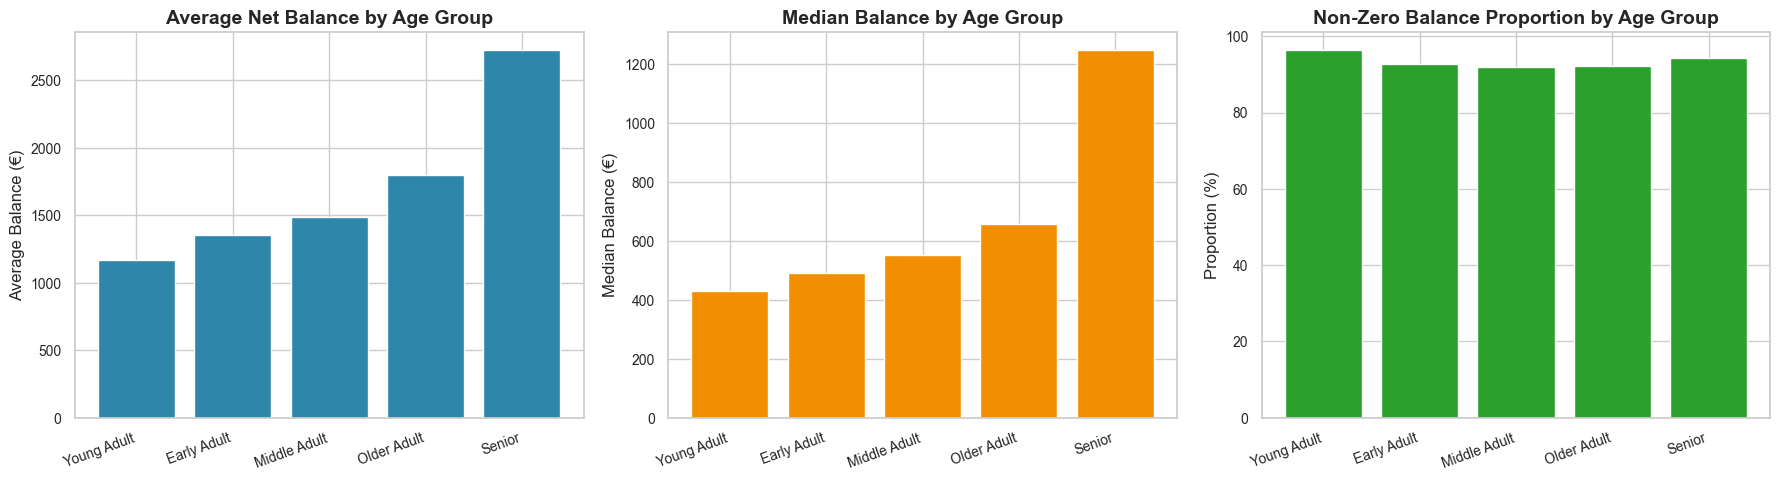

In [96]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
age_groups_ordered = age_bal.index.tolist()
short = [str(x).split('(')[0].strip() for x in age_groups_ordered]

axes[0].bar(range(len(short)), age_bal['Average_Net_Balance'],
            color=COLORS['primary'], edgecolor='white')
axes[0].set_xticks(range(len(short)))
axes[0].set_xticklabels(short, rotation=20, ha='right')
axes[0].set_title('Average Net Balance by Age Group', fontweight='bold')
axes[0].set_ylabel('Average Balance (€)')

axes[1].bar(range(len(short)), age_bal['Median_Balance'],
            color=COLORS['accent'], edgecolor='white')
axes[1].set_xticks(range(len(short)))
axes[1].set_xticklabels(short, rotation=20, ha='right')
axes[1].set_title('Median Balance by Age Group', fontweight='bold')
axes[1].set_ylabel('Median Balance (€)')

axes[2].bar(range(len(short)), age_bal['Non_Zero_Proportion (%)'],
            color=COLORS['success'], edgecolor='white')
axes[2].set_xticks(range(len(short)))
axes[2].set_xticklabels(short, rotation=20, ha='right')
axes[2].set_title('Non-Zero Balance Proportion by Age Group', fontweight='bold')
axes[2].set_ylabel('Proportion (%)')

plt.tight_layout()
plt.show()

### E. Contact-Intensity Performance

In [97]:
ci_bal = bank.groupby('contact_intensity', observed=True).agg(
    Average_Net_Balance=('balance', 'mean'),
    Median_Balance=('balance', 'median'),
    Count=('balance', 'size'),
    Non_Zero_Count=('balance', lambda x: (x != 0).sum())
).round(2)
ci_bal['Non_Zero_Proportion (%)'] = (ci_bal['Non_Zero_Count'] / ci_bal['Count'] * 100).round(2)
print('Balance Performance by Contact Intensity:')
ci_bal

Balance Performance by Contact Intensity:


,Average_Net_Balance,Median_Balance,Count,Non_Zero_Count,Non_Zero_Proportion (%)
contact_intensity,,,,,
Brief,1370.83,458.5,2800,2581,92.18
Standard,1460.30,535.0,2792,2592,92.84
Extended,1665.22,598.0,2783,2618,94.07
Deep-engagement,1618.85,607.0,2787,2597,93.18


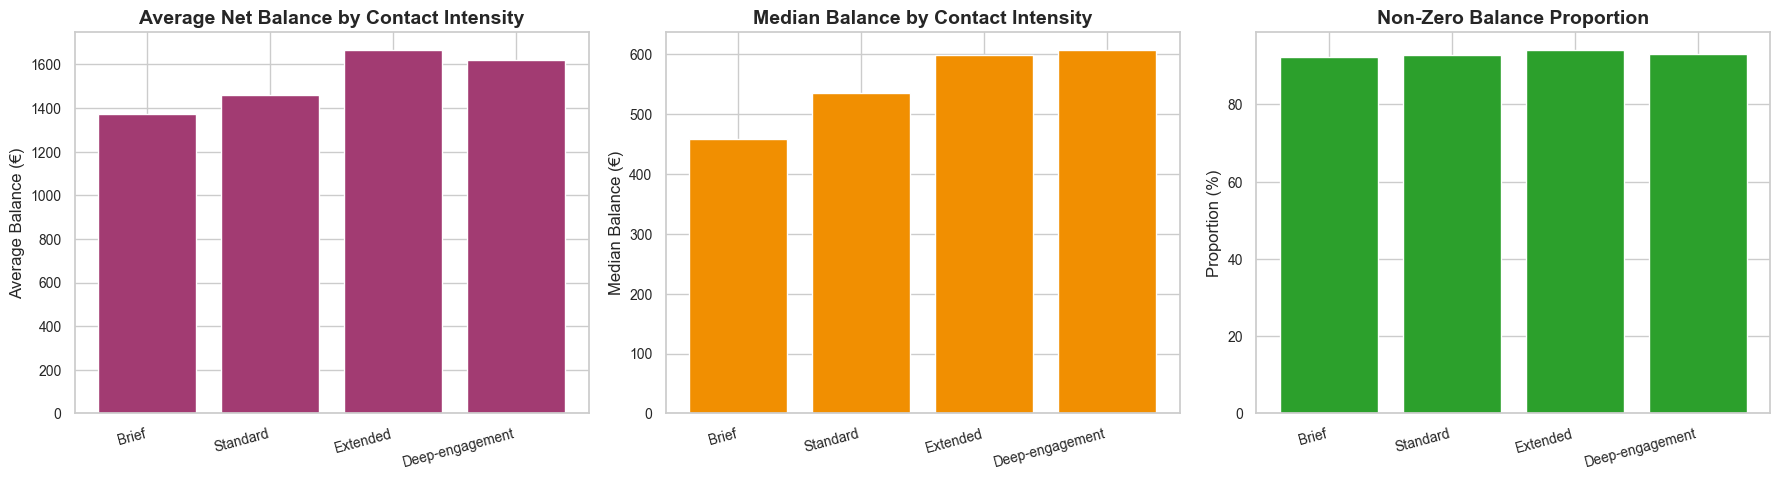

In [98]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ci_groups_ordered = ci_bal.index.tolist()

axes[0].bar(range(len(ci_groups_ordered)), ci_bal['Average_Net_Balance'],
            color=COLORS['secondary'], edgecolor='white')
axes[0].set_xticks(range(len(ci_groups_ordered)))
axes[0].set_xticklabels(ci_groups_ordered, rotation=15, ha='right')
axes[0].set_title('Average Net Balance by Contact Intensity', fontweight='bold')
axes[0].set_ylabel('Average Balance (€)')

axes[1].bar(range(len(ci_groups_ordered)), ci_bal['Median_Balance'],
            color=COLORS['accent'], edgecolor='white')
axes[1].set_xticks(range(len(ci_groups_ordered)))
axes[1].set_xticklabels(ci_groups_ordered, rotation=15, ha='right')
axes[1].set_title('Median Balance by Contact Intensity', fontweight='bold')
axes[1].set_ylabel('Median Balance (€)')

axes[2].bar(range(len(ci_groups_ordered)), ci_bal['Non_Zero_Proportion (%)'],
            color=COLORS['success'], edgecolor='white')
axes[2].set_xticks(range(len(ci_groups_ordered)))
axes[2].set_xticklabels(ci_groups_ordered, rotation=15, ha='right')
axes[2].set_title('Non-Zero Balance Proportion', fontweight='bold')
axes[2].set_ylabel('Proportion (%)')

plt.tight_layout()
plt.show()

### F. Compare Associations

In [99]:
# One-way ANOVA: balance across age groups
age_groups_data = [g['balance'].values for _, g in bank.groupby('age_group', observed=True)]
f_stat_age, p_val_age = stats.f_oneway(*age_groups_data)

# One-way ANOVA: balance across contact intensity groups
ci_groups_data = [g['balance'].values for _, g in bank.groupby('contact_intensity', observed=True)]
f_stat_ci, p_val_ci = stats.f_oneway(*ci_groups_data)

# Eta-squared (effect size)
eta_sq_age = eta_squared(age_groups_data, bank['balance'])
eta_sq_ci = eta_squared(ci_groups_data, bank['balance'])

print('Association Comparison: Grouping Variable → Balance')
print('=' * 55)
print(f'\nAge Group → Balance:')
print(f'  F-statistic: {f_stat_age:.4f}')
print(f'  p-value:     {p_val_age:.6f}')
print(f'  η² (eta-squared): {eta_sq_age:.6f}')
print(f'\nContact Intensity → Balance:')
print(f'  F-statistic: {f_stat_ci:.4f}')
print(f'  p-value:     {p_val_ci:.6f}')
print(f'  η² (eta-squared): {eta_sq_ci:.6f}')

stronger = 'Age group' if eta_sq_age > eta_sq_ci else 'Contact intensity'
print(f'\n→ {stronger} shows a stronger association with balance.')
print('  However, both effect sizes are very small — neither explains')
print('  a large proportion of balance variance.')

Association Comparison: Grouping Variable → Balance

Age Group → Balance:
  F-statistic: 38.6187
  p-value:     0.000000
  η² (eta-squared): 0.013656

Contact Intensity → Balance:
  F-statistic: 5.0478
  p-value:     0.001706
  η² (eta-squared): 0.001355

→ Age group shows a stronger association with balance.
  However, both effect sizes are very small — neither explains
  a large proportion of balance variance.


**Interpretation:** Grouping helps identify broad trends (e.g., older customers may hold higher
balances), but individual variation within each group remains dominant. Neither age group nor
contact intensity is a strong predictor of balance alone.

---
## Question 4 — Final Dataset Refinement and Structure [5 Marks]

**Objective:** Document the refined dataset structure and explain how it improves
interpretability for modelling deposit subscription prediction.

In [100]:
print(f'Original number of rows:    {bank.shape[0]:,}')
print(f'Original number of columns: 17')
print(f'Current number of columns:  {bank.shape[1]}')

new_cols = ['education_group', 'age_group', 'contact_intensity', 'balance_category']
print(f'\nNew derived columns: {new_cols}')

# 'unknown' values report
for col in ['education', 'contact', 'poutcome']:
    n_unknown = (bank[col] == 'unknown').sum()
    print(f'  {col}: {n_unknown} unknown values → retained appropriately')

Original number of rows:    11,162
Original number of columns: 17
Current number of columns:  21

New derived columns: ['education_group', 'age_group', 'contact_intensity', 'balance_category']
  education: 497 unknown values → retained appropriately
  contact: 2346 unknown values → retained appropriately
  poutcome: 8326 unknown values → retained appropriately


In [101]:
# Final summary table
final_info = []
for col in bank.columns:
    final_info.append({
        'Column': col,
        'Data Type': str(bank[col].dtype),
        'Non-Null': bank[col].notna().sum(),
        'Unique Values': bank[col].nunique(),
        'Status': 'New (derived)' if col in new_cols else 'Original'
    })

final_summary = pd.DataFrame(final_info)
print('Final Refined Dataset Structure:')
final_summary

Final Refined Dataset Structure:


,Column,Data Type,Non-Null,Unique Values,Status
0,age,int64,11162,76,Original
1,job,object,11162,12,Original
2,marital,object,11162,3,Original
3,education,object,11162,4,Original
4,default,object,11162,2,Original
5,balance,int64,11162,3805,Original
6,housing,object,11162,2,Original
7,loan,object,11162,2,Original
8,contact,object,11162,3,Original
9,day,int64,11162,31,Original


In [102]:
# Save refined dataset
bank.to_csv('bank_refined.csv', index=False)
print('Refined bank dataset saved as bank_refined.csv')

Refined bank dataset saved as bank_refined.csv


### Dataset Refinement Summary

| Aspect | Detail |
|--------|--------|
| Original shape | 11,162 rows × 17 columns |
| Refined shape | 11,162 rows × 21 columns |
| Rows removed | 0 — all observations are valid |
| Columns removed | 0 — originals preserved for reference |
| New features | `education_group`, `age_group`, `contact_intensity`, `balance_category` |

**How refinement improves the dataset:**
1. Categorical features enable cross-tabulation, group comparisons, and segment profiling.
2. These features are directly usable in classification models predicting deposit subscription.
3. `education_group` resolves the ambiguity of 'unknown' education level.
4. Age groups allow demographic segmentation without losing the original continuous variable.
5. Contact intensity identifies engagement patterns related to campaign success.

---
## Part I — Conclusion

1. **Education**: Secondary (49.1%) dominates; grouping into Basic/Intermediate/Higher/Not-reported improves clarity.
2. **Age & Duration**: No meaningful linear correlation (r ≈ 0). Grouping into life-stage and engagement tiers
   aids interpretation despite information loss.
3. **Balance**: Strongly right-skewed; 87% positive, 6.2% negative, 6.9% zero. Older customers tend to hold
   higher balances. Neither grouping variable strongly predicts balance alone.
4. **Refinement**: Four derived features added. Dataset ready for modelling with enriched categorical structure.